# CS 521 HW4 — Problem 1
NetID: ws39

I compare standard training and IBP on MNIST with three hidden layers of 50 ReLU units.
Run all cells in Colab with a CPU runtime. Both models use the same runtime for timing.
The last cell downloads the results, weights and figures from `results/`.


In [1]:
import copy
import itertools
import json
import os
import platform
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import datasets
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import display, Markdown

SEED = 0
EPOCHS = 40
BATCH_SIZE = 128
import google.colab

DEVICE = "cpu"
torch.set_num_threads(2)
torch.manual_seed(SEED)
np.random.seed(SEED)
torch.use_deterministic_algorithms(True)
device = torch.device(DEVICE)
out = Path("results")
out.mkdir(exist_ok=True)
data_dir = Path(os.environ.get("MNIST_DATA_DIR", "mnist_data"))
train_data = datasets.MNIST(data_dir, train=True, download=True)
test_data = datasets.MNIST(data_dir, train=False, download=True)
train_x = train_data.data.float().flatten(1) / 255
test_x = test_data.data.float().flatten(1) / 255
train_y, test_y = train_data.targets, test_data.targets
test_loader = DataLoader(TensorDataset(test_x, test_y), batch_size=256)
print("Execution environment: Google Colab")
print(f"PyTorch {torch.__version__}; torchvision {torchvision.__version__}")
print(f"{platform.system()} {platform.machine()}; device={device}; threads=2")
print(f"Train: {len(train_y)}; test: {len(test_y)}; seed: {SEED}")

100%|██████████| 9.91M/9.91M [00:00<00:00, 138MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 26.8MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 76.7MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.62MB/s]


Execution environment: Google Colab
PyTorch 2.11.0+cpu; torchvision 0.26.0+cpu
Linux x86_64; device=cpu; threads=2
Train: 60000; test: 10000; seed: 0


## (a) Training
Inputs are pixel values in [0,1], without mean/std normalization. The perturbation
radius is measured in these units. For each affine layer I propagate a box by
its midpoint and radius, then apply ReLU to both endpoints.

For the last layer I directly bound each margin $z_y-z_j$, using the weight
difference $W_y-W_j$. If its lower bound is $m_j$, I set
$\hat z_j=-m_j$ and $\hat z_y=0$. The loss is
$\kappa\,\mathrm{CE}(z,y)+(1-\kappa)\,\mathrm{CE}(\hat z,y)$.
This merges the last layer with the specification, as in Eq. 9 of Gowal et al.

I use Adam (initial learning rate 0.001, reduced to 0.0001 after epoch 30), batch
size 128, and 40 epochs. Epochs 1–2 are clean warm-up. Over epochs 3–20, epsilon
increases linearly from 0 to 0.1 and kappa decreases from 1 to 0.5, using the epoch
schedule below. Both stay fixed for epochs 21–40. The standard baseline uses the
same initialization, shuffled batches, optimizer and learning-rate schedule.
Timing includes the training loop, but excludes dataset preparation, evaluation and saving.

In [2]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden = nn.ModuleList([nn.Linear(784, 50), nn.Linear(50, 50),
                                     nn.Linear(50, 50)])
        self.output = nn.Linear(50, 10)

    def forward(self, x):
        x = x.flatten(1)
        for layer in self.hidden:
            x = F.relu(layer(x))
        return self.output(x)


def ibp_logits(net, x, y, eps):
    lower, upper = (x - eps).clamp(0, 1), (x + eps).clamp(0, 1)
    for layer in net.hidden:
        center, radius = (lower + upper) / 2, (upper - lower) / 2
        center = F.linear(center, layer.weight, layer.bias)
        radius = F.linear(radius, layer.weight.abs())
        lower, upper = (center - radius).relu(), (center + radius).relu()
    center, radius = (lower + upper) / 2, (upper - lower) / 2
    # Bound z_j - z_y, including an exactly zero entry for j=y.
    weight = net.output.weight[None] - net.output.weight[y, None]
    bias = net.output.bias[None] - net.output.bias[y, None]
    return (weight * center[:, None]).sum(2) + (weight.abs() * radius[:, None]).sum(2) + bias


def schedule(epoch):
    progress = min(max((epoch - 2) / 18, 0), 1)
    return 0.1 * progress, 1 - 0.5 * progress


def synchronize():
    if device.type == "cuda":
        torch.cuda.synchronize()


def train(initial_state, robust):
    net = Net().to(device)
    net.load_state_dict(initial_state)
    loader = DataLoader(TensorDataset(train_x, train_y), batch_size=BATCH_SIZE,
                        shuffle=True, generator=torch.Generator().manual_seed(SEED))
    optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)
    scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[30], gamma=0.1)
    history = []
    for epoch in range(1, EPOCHS + 1):
        eps, kappa = schedule(epoch) if robust else (0.0, 1.0)
        net.train()
        total = 0.0
        synchronize()
        start = time.perf_counter()
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad(set_to_none=True)
            clean_loss = F.cross_entropy(net(x), y)
            loss = clean_loss
            if kappa < 1:
                loss = kappa * clean_loss + (1 - kappa) * F.cross_entropy(ibp_logits(net, x, y, eps), y)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(y)
        synchronize()
        elapsed = time.perf_counter() - start
        history.append(dict(epoch=epoch, loss=total / len(train_y), epsilon=eps,
                            kappa=kappa, seconds=elapsed, lr=optimizer.param_groups[0]["lr"]))
        scheduler.step()
        print(f"{'IBP' if robust else 'Standard':8s} {epoch:2d}: loss={total/len(train_y):.4f}, "
              f"eps={eps:.4f}, kappa={kappa:.3f}, seconds={elapsed:.2f}", flush=True)
    return net.eval(), history


torch.manual_seed(SEED)
initial_state = copy.deepcopy(Net().state_dict())
standard, standard_history = train(initial_state, False)
torch.save(standard.cpu().state_dict(), out / "standard.pt")
(out / "standard_history.json").write_text(json.dumps(standard_history, indent=2))
standard.to(device)
ibp, ibp_history = train(initial_state, True)
torch.save(ibp.cpu().state_dict(), out / "ibp.pt")
(out / "ibp_history.json").write_text(json.dumps(ibp_history, indent=2))
ibp.to(device)

Standard  1: loss=0.5517, eps=0.0000, kappa=1.000, seconds=6.91
Standard  2: loss=0.2341, eps=0.0000, kappa=1.000, seconds=2.75
Standard  3: loss=0.1731, eps=0.0000, kappa=1.000, seconds=2.63
Standard  4: loss=0.1375, eps=0.0000, kappa=1.000, seconds=5.26
Standard  5: loss=0.1148, eps=0.0000, kappa=1.000, seconds=2.59
Standard  6: loss=0.0970, eps=0.0000, kappa=1.000, seconds=2.79
Standard  7: loss=0.0865, eps=0.0000, kappa=1.000, seconds=2.59
Standard  8: loss=0.0746, eps=0.0000, kappa=1.000, seconds=5.10
Standard  9: loss=0.0690, eps=0.0000, kappa=1.000, seconds=3.53
Standard 10: loss=0.0604, eps=0.0000, kappa=1.000, seconds=3.05
Standard 11: loss=0.0550, eps=0.0000, kappa=1.000, seconds=2.42
Standard 12: loss=0.0498, eps=0.0000, kappa=1.000, seconds=5.00
Standard 13: loss=0.0438, eps=0.0000, kappa=1.000, seconds=2.97
Standard 14: loss=0.0416, eps=0.0000, kappa=1.000, seconds=2.58
Standard 15: loss=0.0371, eps=0.0000, kappa=1.000, seconds=2.61
Standard 16: loss=0.0346, eps=0.0000, ka

Net(
  (hidden): ModuleList(
    (0): Linear(in_features=784, out_features=50, bias=True)
    (1-2): 2 x Linear(in_features=50, out_features=50, bias=True)
  )
  (output): Linear(in_features=50, out_features=10, bias=True)
)

## (b) Box verification
I adapted my HW2 verifier to the three hidden layers. It uses positive/negative
weight splitting and bounds the nine true-label margins directly. Verification
uses float64, with a margin threshold of $10^{-9}$.


In [3]:
def affine_bounds(lower, upper, weight, bias):
    positive, negative = weight.clamp(min=0), weight.clamp(max=0)
    return (F.linear(lower, positive, bias) + F.linear(upper, negative),
            F.linear(upper, positive, bias) + F.linear(lower, negative))


@torch.no_grad()
def margin_bounds(net, x, y, eps):
    x = x.to(dtype=net.output.weight.dtype, device=net.output.weight.device)
    y = y.to(x.device)
    lower, upper = (x - eps).clamp(0, 1), (x + eps).clamp(0, 1)
    for layer in net.hidden:
        lower, upper = affine_bounds(lower, upper, layer.weight, layer.bias)
        lower, upper = lower.relu(), upper.relu()
    classes = torch.arange(10, device=x.device).expand(len(x), 10)
    others = classes[classes != y[:, None]].reshape(-1, 9)
    weight = net.output.weight[y, None] - net.output.weight[others]
    bias = net.output.bias[y, None] - net.output.bias[others]
    positive, negative = weight.clamp(min=0), weight.clamp(max=0)
    return ((positive * lower[:, None] + negative * upper[:, None]).sum(2) + bias,
            (positive * upper[:, None] + negative * lower[:, None]).sum(2) + bias)


verifier = copy.deepcopy(ibp).cpu().double().eval()
# Exact affine extrema at all corners of a three-dimensional box.
lo = torch.tensor([[-1., 0., 2.]], dtype=torch.float64)
hi = torch.tensor([[2., 3., 4.]], dtype=torch.float64)
w = torch.tensor([[2., -3., 1.], [-1., 0., -2.]], dtype=torch.float64)
b = torch.tensor([0.5, -0.5], dtype=torch.float64)
corners = torch.tensor(list(itertools.product(*zip(lo[0].tolist(), hi[0].tolist()))))
values = F.linear(corners.double(), w, b)
lower, upper = affine_bounds(lo, hi, w, b)
torch.testing.assert_close(lower[0], values.amin(0))
torch.testing.assert_close(upper[0], values.amax(0))

# Zero-radius intervals equal the exact margins on every test image.
for x, y in test_loader:
    z = verifier(x.double()).detach()
    mask = torch.arange(10)[None] != y[:, None]
    exact = (z.gather(1, y[:, None]) - z)[mask].reshape(-1, 9)
    lo, hi = margin_bounds(verifier, x, y, 0)
    torch.testing.assert_close(lo, exact, atol=1e-10, rtol=1e-10)
    torch.testing.assert_close(hi, exact, atol=1e-10, rtol=1e-10)

# Compare the two bound implementations and check perturbed inputs.
torch.manual_seed(123)
x, y = test_x[:32].double(), test_y[:32]
mask = torch.arange(10)[None] != y[:, None]
for eps in (0, 0.01, 0.05, 0.10):
    lo, hi = margin_bounds(verifier, x, y, eps)
    training_bounds = -ibp_logits(verifier, x, y, eps)[mask].reshape(-1, 9)
    torch.testing.assert_close(training_bounds, lo, atol=1e-10, rtol=1e-10)
    for _ in range(10):
        perturbed = (x + (2 * torch.rand_like(x) - 1) * eps).clamp(0, 1)
        z = verifier(perturbed).detach()
        margins = (z.gather(1, y[:, None]) - z)[mask].reshape(-1, 9)
        assert (margins >= lo - 1e-10).all() and (margins <= hi + 1e-10).all()
print("Passed affine corners, zero-radius margins, independent bounds, and sampled perturbations.")

@torch.no_grad()
def predictions(net):
    return torch.cat([net(x.to(device)).argmax(1).cpu() for x, _ in test_loader])

clean_standard = predictions(standard).eq(test_y)
clean_ibp = predictions(ibp).eq(test_y)
epsilons = [i / 100 for i in range(1, 11)]
certificates = []
for eps in epsilons:
    bounds = torch.cat([margin_bounds(verifier, x, y, eps)[0] for x, y in test_loader])
    cert = bounds.amin(1) > 1e-9
    assert not (cert & ~clean_ibp).any()
    if certificates:
        assert not (cert & ~certificates[-1]).any()
    certificates.append(cert)
    print(f"eps={eps:.2f}: verified={int(cert.sum())}/10000 ({100*cert.double().mean():.2f}%)")

Passed affine corners, zero-radius margins, independent bounds, and sampled perturbations.
eps=0.01: verified=9432/10000 (94.32%)
eps=0.02: verified=9356/10000 (93.56%)
eps=0.03: verified=9259/10000 (92.59%)
eps=0.04: verified=9149/10000 (91.49%)
eps=0.05: verified=9046/10000 (90.46%)
eps=0.06: verified=8901/10000 (89.01%)
eps=0.07: verified=8754/10000 (87.54%)
eps=0.08: verified=8578/10000 (85.78%)
eps=0.09: verified=8352/10000 (83.52%)
eps=0.10: verified=8125/10000 (81.25%)


## PGD evaluation and counterexamples
I use untargeted cross-entropy PGD: 50 steps, three random restarts, and step size
$\epsilon/10$. Every step is projected onto both the input box and [0,1]. An
image fails if **any iterate** misclassifies it; clean errors also count as failures.
For the IBP model I attack every test image at each of the ten radii. I also keep
successful attacks from smaller radii, since they remain valid at larger radii.
The baseline is attacked at epsilon 0.1. PGD accuracy is an attack-based upper
bound on robust accuracy, while verified accuracy is a lower bound.

In [4]:
def pgd(net, x, y, eps, steps=50, restarts=3):
    x, y = x.to(device), y.to(device)
    lo, hi = (x - eps).clamp(0, 1), (x + eps).clamp(0, 1)
    with torch.no_grad():
        failed = net(x).argmax(1).ne(y)
    witness = x.clone()
    for _ in range(restarts):
        adv = lo + torch.rand_like(x) * (hi - lo)
        for step in range(steps + 1):
            adv = adv.detach().requires_grad_(True)
            logits = net(adv)
            with torch.no_grad():
                wrong = logits.argmax(1).ne(y)
                witness[wrong] = adv.detach()[wrong]
                failed |= wrong
            if step == steps:
                break
            grad = torch.autograd.grad(F.cross_entropy(logits, y), adv)[0]
            adv = torch.maximum(torch.minimum(adv.detach() + eps / 10 * grad.sign(), hi), lo)
    assert (witness - x).abs().max() <= eps + 1e-6
    assert witness.min() >= 0 and witness.max() <= 1
    with torch.no_grad():
        assert net(witness[failed]).argmax(1).ne(y[failed]).all()
    return failed.cpu(), witness.cpu()


def attack_dataset(net, eps, previous=None):
    failed_list, witnesses = [], []
    for x, y in test_loader:
        failed, witness = pgd(net, x, y, eps)
        failed_list.append(failed)
        witnesses.append(witness)
    failed, witness = torch.cat(failed_list), torch.cat(witnesses)
    if previous is not None:
        prev_failed, prev_witness = previous
        keep = prev_failed & ~failed
        witness[keep] = prev_witness[keep]
        failed |= prev_failed
    return failed, witness


torch.manual_seed(2026)
start = time.perf_counter()
standard_failed, _ = attack_dataset(standard, 0.1)
print(f"Standard: clean={100*clean_standard.double().mean():.2f}%, "
      f"PGD={100*(~standard_failed).double().mean():.2f}%", flush=True)
results, examples, all_failures = [], [], []
previous = None
for eps, cert in zip(epsilons, certificates):
    failed, witness = attack_dataset(ibp, eps, previous)
    previous = (failed, witness)
    # A found counterexample must never have a certificate.
    assert not (cert & failed).any()
    row = dict(epsilon=eps, verified_count=int(cert.sum()),
               pgd_correct_count=int((~failed).sum()),
               clean_correct_attacked=int((clean_ibp & failed).sum()),
               unresolved_count=int((~cert & ~failed).sum()))
    results.append(row)
    all_failures.append(failed)
    print(f"eps={eps:.2f}: verified={row['verified_count']/100:.2f}%, "
          f"PGD={row['pgd_correct_count']/100:.2f}%, "
          f"unresolved={row['unresolved_count']}", flush=True)
    if eps in (0.01, 0.05, 0.1):
        indices = torch.where(clean_ibp & failed & ~cert)[0]
        if len(indices):
            idx = int(indices[0])
            with torch.no_grad():
                pred = int(ibp(witness[idx:idx+1].to(device)).argmax(1))
                clean_pred = int(ibp(test_x[idx:idx+1].to(device)).argmax(1))
            examples.append(dict(index=idx, epsilon=eps, label=int(test_y[idx]),
                                 prediction=pred, clean_prediction=clean_pred,
                                 linf=float((witness[idx] - test_x[idx]).abs().max()),
                                 image=witness[idx].numpy()))
    (out / "radius_results.json").write_text(json.dumps(results, indent=2))

summary = dict(execution_environment="Google Colab", seed=SEED, epochs=EPOCHS, batch_size=BATCH_SIZE, device=str(device),
               threads=2, torch_version=torch.__version__, torchvision_version=torchvision.__version__,
               platform=platform.platform(), train_size=len(train_y), test_size=len(test_y),
               architecture=[784,50,50,50,10], pgd_steps=50, pgd_restarts=3,
               pgd_step_size="epsilon / 10", attack_seed=2026,
               standard_clean_count=int(clean_standard.sum()), ibp_clean_count=int(clean_ibp.sum()),
               standard_pgd_count=int((~standard_failed).sum()),
               standard_training_seconds=sum(r['seconds'] for r in standard_history),
               ibp_training_seconds=sum(r['seconds'] for r in ibp_history),
               attack_seconds=time.perf_counter()-start, results=results,
               examples=[{k:v for k,v in e.items() if k!='image'} for e in examples])
(out / "summary.json").write_text(json.dumps(summary, indent=2))
np.savez_compressed(out / "verification_and_attacks.npz", epsilons=epsilons,
                    certified=torch.stack(certificates).numpy(),
                    attack_failed=torch.stack(all_failures).numpy(),
                    clean_correct=clean_ibp.numpy(), labels=test_y.numpy(),
                    example_images=np.stack([e['image'] for e in examples]))
print("All attack witnesses satisfy the radius constraint; no certified image was attacked successfully.")

Standard: clean=97.32%, PGD=0.52%
eps=0.01: verified=94.32%, PGD=94.34%, unresolved=2
eps=0.02: verified=93.56%, PGD=93.71%, unresolved=15
eps=0.03: verified=92.59%, PGD=92.94%, unresolved=35
eps=0.04: verified=91.49%, PGD=92.05%, unresolved=56
eps=0.05: verified=90.46%, PGD=91.26%, unresolved=80
eps=0.06: verified=89.01%, PGD=90.20%, unresolved=119
eps=0.07: verified=87.54%, PGD=89.01%, unresolved=147
eps=0.08: verified=85.78%, PGD=87.90%, unresolved=212
eps=0.09: verified=83.52%, PGD=86.19%, unresolved=267
eps=0.10: verified=81.25%, PGD=84.68%, unresolved=343
All attack witnesses satisfy the radius constraint; no certified image was attacked successfully.


Model     Clean (%)  PGD at 0.1 (%)  Training (s)
Standard     97.32            0.52        131.11
IBP          94.98           84.68        252.22


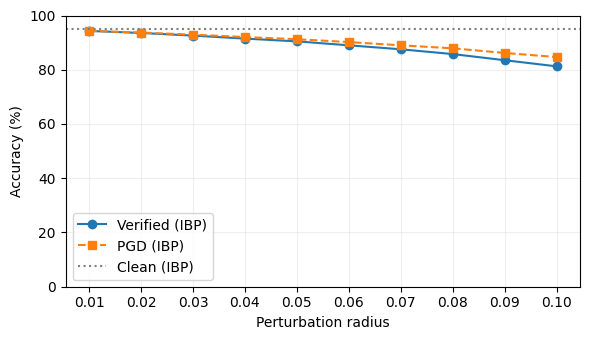

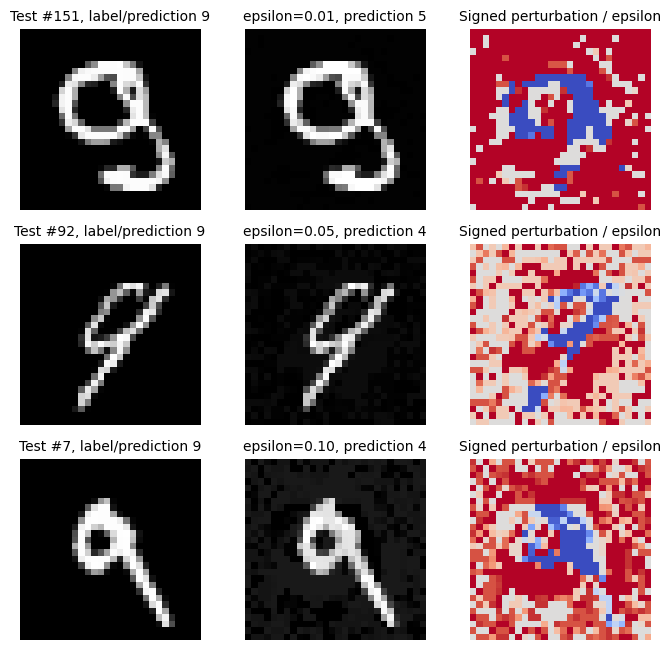

IBP takes **1.92 times** the training time of the standard model. At epsilon 0.1, its clean, PGD and verified accuracies are **94.98%**, **84.68%**, and **81.25%**, respectively. There are **343** images that are neither certified nor successfully attacked. Failure to certify alone does not establish non-robustness; a failed PGD search does not prove robustness either. The displayed examples were initially classified correctly and are misclassified after a perturbation within the stated radius. The third column rescales the perturbation for visibility; it is not the actual perturbed image.

In [5]:
print("Model     Clean (%)  PGD at 0.1 (%)  Training (s)")
for name, clean, attacked, history in [
        ("Standard", clean_standard, standard_failed, standard_history),
        ("IBP", clean_ibp, all_failures[-1], ibp_history)]:
    print(f"{name:8s}  {100*clean.double().mean():8.2f}  "
          f"{100*(~attacked).double().mean():14.2f}  {sum(r['seconds'] for r in history):12.2f}")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(epsilons, [r['verified_count']/100 for r in results], 'o-', label='Verified (IBP)')
ax.plot(epsilons, [r['pgd_correct_count']/100 for r in results], 's--', label='PGD (IBP)')
ax.axhline(100*clean_ibp.double().mean(), color='gray', linestyle=':', label='Clean (IBP)')
ax.set(xlabel='Perturbation radius', ylabel='Accuracy (%)', ylim=(0,100), xticks=epsilons)
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
fig.savefig(out / 'accuracy.png', dpi=180)
plt.show()

fig, axes = plt.subplots(len(examples), 3, figsize=(7, 2.2*len(examples)), squeeze=False)
for row, e in enumerate(examples):
    original = test_x[e['index']].reshape(28,28).numpy()
    adv = e['image'].reshape(28,28)
    axes[row,0].imshow(original, cmap='gray', vmin=0, vmax=1)
    axes[row,1].imshow(adv, cmap='gray', vmin=0, vmax=1)
    axes[row,2].imshow((adv-original)/e['epsilon'], cmap='coolwarm', vmin=-1, vmax=1)
    axes[row,0].set_title(f"Test #{e['index']}, label/prediction {e['label']}", fontsize=10)
    axes[row,1].set_title(f"epsilon={e['epsilon']:.2f}, prediction {e['prediction']}", fontsize=10)
    axes[row,2].set_title('Signed perturbation / epsilon', fontsize=10)
    for ax in axes[row]: ax.axis('off')
fig.tight_layout()
fig.savefig(out / 'adversarial_examples.png', dpi=180)
plt.show()

ratio = summary['ibp_training_seconds'] / summary['standard_training_seconds']
last = results[-1]
display(Markdown(
    f"IBP takes **{ratio:.2f} times** the training time of the standard model. "
    f"At epsilon 0.1, its clean, PGD and verified accuracies are "
    f"**{summary['ibp_clean_count']/100:.2f}%**, **{last['pgd_correct_count']/100:.2f}%**, "
    f"and **{last['verified_count']/100:.2f}%**, respectively. "
    f"There are **{last['unresolved_count']}** images that are neither certified nor "
    "successfully attacked. Failure to certify alone does not establish non-robustness; "
    "a failed PGD search does not prove robustness either. "
    "The displayed examples were initially classified correctly and are misclassified "
    "after a perturbation within the stated radius. The third column rescales the "
    "perturbation for visibility; it is not the actual perturbed image."
))

### Results
Larger input boxes give looser bounds because IBP loses dependencies between neurons.
An unresolved image has neither a certificate nor a counterexample found by PGD.

For each displayed radius, I show the first successful attack on an initially correct
image. The rescaled perturbation makes small changes easier to see.


## References
- Gowal et al. (2019), *On the Effectiveness of Interval Bound Propagation for Training
  Verifiably Robust Models*, Eqs. 9 and 12: https://arxiv.org/abs/1810.12715
- My HW2 notebook (box verifier adapted to three hidden layers):
  https://github.com/Weipeng-Su/CS521FA26HW/blob/main/hw2/problem4/mnist_interval_analysis.ipynb
- Assignment's example implementation (consulted for context):
  https://github.com/Zinoex/bound_propagation/blob/main/examples/fashion_mnist.py


In [6]:
import shutil
from google.colab import files
shutil.make_archive("problem1_results", "zip", "results")
files.download("problem1_results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>